# Regressão Logística no dataset Breast Cancer


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

## 1. Análise dos dados

In [2]:
dados = load_breast_cancer(as_frame=True)
X, y = dados.data, dados.target

print('Shape de X:', X.shape)
print('Classes:', dados.target_names)
print(y.value_counts())

X.head()

Shape de X: (569, 30)
Classes: ['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


O dataset tem 569 amostras e 30 colunas numéricas. São 212 casos da classe 0, que é maligno, e 357 da classe 1, que é benigno.

As variáveis são medidas tiradas de imagens dos núcleos das células do tumor. Por exemplo, mean radius é o raio médio, mean texture é a textura média da imagem, mean perimeter e mean area são o perímetro e a área média, e mean smoothness mede o quão liso ou irregular é o contorno.

## 2. Divisão treino/teste e padronização

Separei 80% para treino e 20% para teste com stratify=y para manter a proporção das classes nos dois conjuntos. O StandardScaler foi ajustado só no treino com fit_transform, e no teste apliquei apenas transform.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.long)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.long)

print('Treino:', X_train_t.shape, 'Teste:', X_test_t.shape)

Treino: torch.Size([455, 30]) Teste: torch.Size([114, 30])


## 3. Treinamento com SGD

In [4]:
model = nn.Linear(30, 2)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

n_epochs = 500
train_losses = []
test_losses = []

for epoch in range(n_epochs):
    model.train()
    out_train = model(X_train_t)
    loss_train = criterion(out_train, y_train_t)

    optimizer.zero_grad()
    loss_train.backward()
    optimizer.step()

    train_losses.append(loss_train.item())

    model.eval()
    with torch.no_grad():
        out_test = model(X_test_t)
        loss_test = criterion(out_test, y_test_t)
        test_losses.append(loss_test.item())

print(f'Custo final treino: {train_losses[-1]:.4f}')
print(f'Custo final teste:  {test_losses[-1]:.4f}')

Custo final treino: 0.0568
Custo final teste:  0.0874


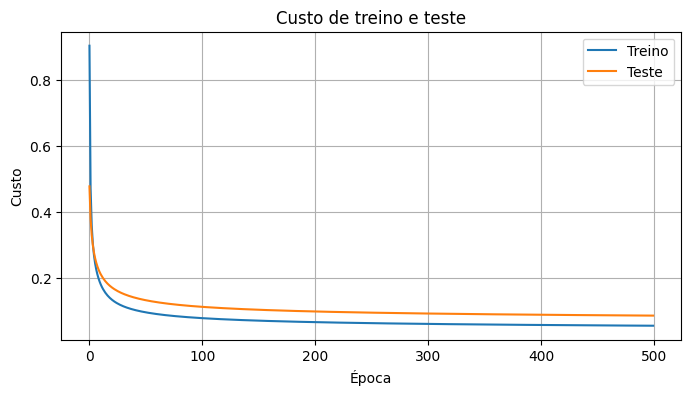

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label='Treino')
plt.plot(test_losses, label='Teste')
plt.xlabel('Época')
plt.ylabel('Custo')
plt.title('Custo de treino e teste')
plt.legend()
plt.grid(True)
plt.show()

## 4. Acurácia no teste e baseline

In [6]:
model.eval()
with torch.no_grad():
    y_pred = model(X_test_t).argmax(dim=1).numpy()

y_true = y_test.values

acc = (y_pred == y_true).mean()

classe_mais_freq = y_train.value_counts().idxmax()
baseline_acc = (y_true == classe_mais_freq).mean()

print(f'Acurácia no teste: {acc*100:.2f}%')
print(f'Baseline (classe {classe_mais_freq}): {baseline_acc*100:.2f}%')

Acurácia no teste: 96.49%
Baseline (classe 1): 63.16%


A acurácia ficou em 96,49%, bem acima dos 63,16% do baseline que sempre chuta a classe mais frequente, que é benigno.

## 5. Matriz de confusão e recall da classe maligno

In [7]:
cm = pd.crosstab(
    pd.Series(y_pred, name='Previsto'),
    pd.Series(y_true, name='Real')
)
cm

Real,0,1
Previsto,,
0,41,3
1,1,69


In [8]:
acertos_maligno = ((y_true == 0) & (y_pred == 0)).sum()
total_maligno = (y_true == 0).sum()
recall_maligno = acertos_maligno / total_maligno

print(f'Total de malignos no teste: {total_maligno}')
print(f'Malignos encontrados: {acertos_maligno}')
print(f'Recall maligno: {recall_maligno*100:.2f}%')

Total de malignos no teste: 42
Malignos encontrados: 41
Recall maligno: 97.62%


Dos 42 tumores malignos do teste, o modelo acertou 41, o que dá 97,62% de recall. Ou seja, de cada 100 tumores malignos, ele consegue pegar cerca de 97 ou 98.

## 6. Discussão

Nesse problema o erro mais grave é o falso negativo, que é quando o tumor é maligno mas o modelo classifica como benigno. Isso é muito perigoso porque o paciente pode achar que está tudo certo e demorar para começar o tratamento. Já o falso positivo, quando o tumor é benigno mas o modelo marca como maligno, vai gerar preocupação e exames a mais, só que depois nos exames médicos acaba se descobrindo que não era câncer.

Para reduzir os falsos negativos, dá para baixar o limiar de probabilidade na hora de classificar como maligno. Em vez de só marcar como maligno acima de 50%, pode marcar a partir de 30% ou 40%.